# Lab 3: Clustering Analysis Using K-Means and K-Medoids

**Name:** Sai Sravani P
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**Lab Assignment:** Lab 3 – Clustering the Wine Dataset with K-Means and K-Medoids

In this lab I cluster the Wine dataset from scikit-learn using K-Means and K-Medoids with k = 3. I evaluate both models with the Silhouette Score and the Adjusted Rand Index (ARI), visualize the clusters, and compare the results.

In [1]:
%pip install "numpy<2"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# KMedoids comes from the scikit-learn-extra package (pip install scikit-learn-extra)
from sklearn_extra.cluster import KMedoids

# scikit-learn-extra shows a harmless FutureWarning with newer scikit-learn versions
warnings.filterwarnings("ignore", category=FutureWarning)

# Fixed random seed so the results can be reproduced
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Step 1: Load and Prepare the Dataset

The Wine dataset has 178 wine samples from three different cultivars (grape varieties) grown in the same region of Italy. Each sample has 13 chemical measurements.

In [3]:
# Load the data as a DataFrame so the feature names are kept
wine = load_wine(as_frame=True)
X = wine.data      # 13 features
y = wine.target    # true class labels (only used later to calculate ARI)

print("Shape of the data:", X.shape)
print("Class names:", [str(name) for name in wine.target_names])
X.head()

Shape of the data: (178, 13)
Class names: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 1.1 Feature details

In [4]:
# Data types and non-null counts for each feature
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

In [5]:
# Summary statistics for each feature
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


All 13 features are numeric, but their scales are very different. For example, `proline` goes from 278 to 1680, while `hue` stays between about 0.5 and 1.7. Both K-Means and K-Medoids use distances, so without scaling, large-valued features like `proline` would control the results. This is why I standardize the data in Section 1.4.

### 1.2 Class distribution

class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


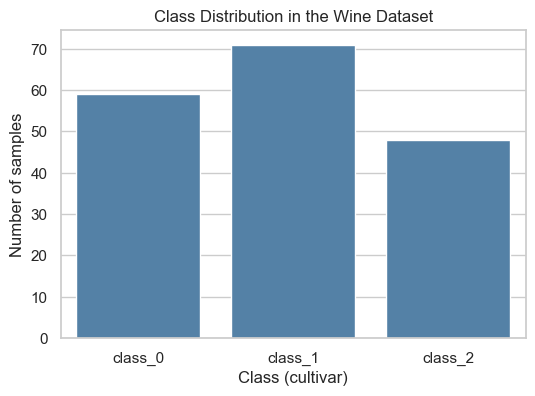

In [6]:
# Number of samples in each class
class_counts = y.value_counts().sort_index()
class_counts.index = wine.target_names
print(class_counts)

plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Class Distribution in the Wine Dataset")
plt.xlabel("Class (cultivar)")
plt.ylabel("Number of samples")
plt.show()

The classes are a little unbalanced (59, 71 and 48 samples), but every class has a reasonable number of samples. Since there are 3 classes, using k = 3 clusters makes sense.

### 1.3 Checking for missing values, duplicates and outliers

In [7]:
# Missing values and duplicate rows
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

Missing values: 0
Duplicate rows: 0


There are no missing values and no duplicate rows, so no imputation or row removal is needed. Next I check for outliers, since outliers can affect clustering (especially K-Means, because its centers are averages).

In [8]:
# Outliers using the IQR rule: values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
iqr_outliers = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).sum()

# Outliers using z-scores: values more than 3 standard deviations from the mean
z_scores = (X - X.mean()) / X.std()
z_outliers = (z_scores.abs() > 3).sum()

outliers = pd.DataFrame({"IQR outliers": iqr_outliers, "z-score outliers (|z| > 3)": z_outliers})
print(outliers[outliers.sum(axis=1) > 0])
print("\nRows with at least one |z| > 3 value:", (z_scores.abs() > 3).any(axis=1).sum())

                   IQR outliers  z-score outliers (|z| > 3)
malic_acid                    3                           1
ash                           3                           3
alcalinity_of_ash             4                           1
magnesium                     4                           2
flavanoids                    0                           1
proanthocyanins               2                           1
color_intensity               4                           1
hue                           1                           1

Rows with at least one |z| > 3 value: 10


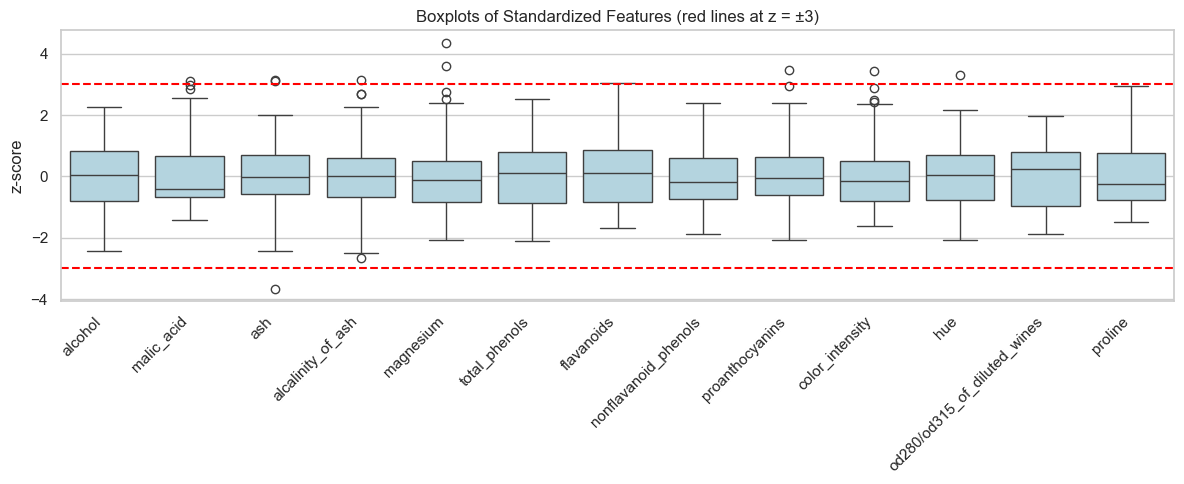

In [9]:
# Boxplots of the z-scored features to see the outliers on the same scale
plt.figure(figsize=(12, 5))
sns.boxplot(data=z_scores, color="lightblue")
plt.axhline(3, color="red", linestyle="--")
plt.axhline(-3, color="red", linestyle="--")
plt.title("Boxplots of Standardized Features (red lines at z = ±3)")
plt.ylabel("z-score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Decision: I kept the outliers.** About 10 of the 178 rows have an extreme value, mostly in `magnesium`, `ash`, `malic_acid` and `alcalinity_of_ash`. I did not remove them because:
- The values look like real measurements, not data entry errors (for example, the highest magnesium values are 151 and 162, which are possible for wine).
- The dataset is small, so removing rows would lose useful information.
- One difference between K-Means and K-Medoids is how they handle outliers, so keeping them makes the comparison more meaningful.

### 1.4 Standardizing the data (z-score normalization)

I use `StandardScaler`, which changes each feature to z = (x − mean) / standard deviation. After this, every feature has a mean of 0 and a standard deviation of 1, so all features count equally in the distance calculations.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check that each feature now has mean 0 and standard deviation 1
print("Feature means after scaling:", np.abs(X_scaled.mean(axis=0)).round(2))
print("Feature standard deviations after scaling:", X_scaled.std(axis=0).round(2))

Feature means after scaling: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Feature standard deviations after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 1.5 Checking that k = 3 is a good choice

The assignment uses k = 3 because there are 3 classes. To check that this also fits the data, I ran K-Means for k = 2 to 8 and looked at the elbow plot and the silhouette score.

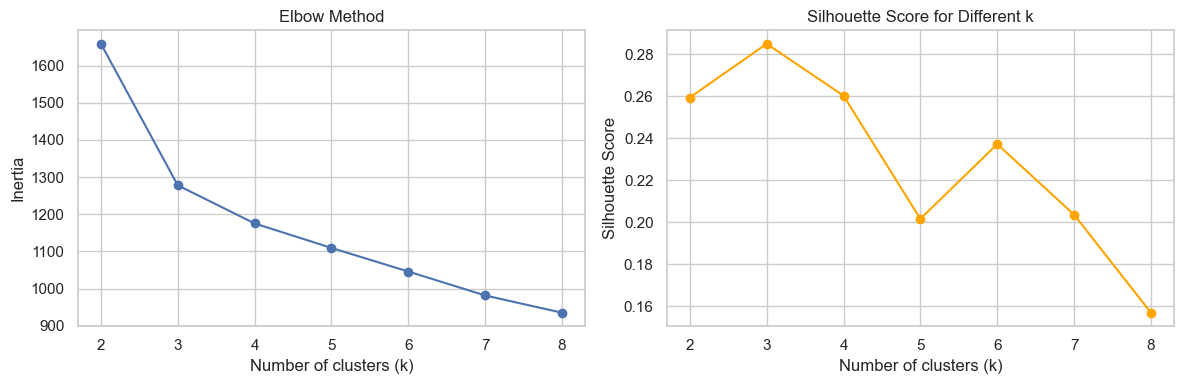

k = 2: silhouette = 0.259
k = 3: silhouette = 0.285
k = 4: silhouette = 0.260
k = 5: silhouette = 0.202
k = 6: silhouette = 0.237
k = 7: silhouette = 0.204
k = 8: silhouette = 0.157


In [11]:
k_values = range(2, 9)
inertia_list = []
silhouette_list = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertia_list, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_list, marker="o", color="orange")
axes[1].set_title("Silhouette Score for Different k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

for k, s in zip(k_values, silhouette_list):
    print(f"k = {k}: silhouette = {s:.3f}")

The silhouette score is highest at k = 3, and the elbow plot also bends at k = 3. This agrees with the 3 classes in the dataset, so k = 3 is a good choice.

## Step 2: K-Means Clustering

K-Means places k centers, assigns each point to its nearest center, and then moves each center to the **mean** of its points. It repeats these two steps until the centers stop changing.

**Parameters used:**
- `n_clusters=3`: the dataset has 3 classes, and the check in Section 1.5 also supports k = 3.
- `init="k-means++"`: chooses starting centers that are spread out, which gives better and faster results than random starting points.
- `n_init=10`: runs K-Means 10 times with different starting points and keeps the best result, which avoids a bad result from an unlucky start.
- `random_state=42`: makes the results reproducible.

In [12]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Number of points in each cluster:", np.bincount(kmeans_labels))

Number of points in each cluster: [65 51 62]


In [13]:
# Silhouette Score: how well separated the clusters are (-1 to 1, higher is better)
# ARI: how well the clusters match the true classes (1 = perfect match, 0 = random)
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print(f"K-Means Silhouette Score: {kmeans_silhouette:.3f}")
print(f"K-Means ARI: {kmeans_ari:.3f}")

K-Means Silhouette Score: 0.285
K-Means ARI: 0.897


In [14]:
# Compare the clusters with the true classes
# (cluster numbers are random, so we look at the pattern, not the numbers)
pd.crosstab(y.map(dict(enumerate(wine.target_names))), kmeans_labels,
            rownames=["True class"], colnames=["K-Means cluster"])

K-Means cluster,0,1,2
True class,,,
class_0,0,0,59
class_1,65,3,3
class_2,0,48,0


K-Means matches the true classes very well. All of `class_0` and `class_2` are each in their own cluster, and only 6 of the 71 `class_1` wines are put in the wrong cluster. That is 172 out of 178 correct (about 96.6%), which explains the high ARI of 0.897.

The silhouette score of 0.285 is only moderate. This is normal for data with 13 features where the classes overlap a bit. It means the clusters are real but not very far apart.

## Step 3: K-Medoids Clustering

K-Medoids works like K-Means, but each cluster center has to be an **actual data point**, called the medoid. The medoid is the point with the smallest total distance to the other points in its cluster. Because the center is a real point and not an average, it is less affected by outliers.

**Parameters used:**
- `n_clusters=3`: same as K-Means so the two models can be compared fairly.
- `metric="euclidean"`: the same distance K-Means uses, so any difference in results comes from the algorithm and not from the distance measure.
- `method="pam"`: PAM (Partitioning Around Medoids) is the standard K-Medoids algorithm. It tries swapping medoids with other points and keeps any swap that improves the clusters. It is slower than the `"alternate"` method, but it is more accurate and is fast enough for 178 samples.
- `init="k-medoids++"`: spreads out the starting medoids, like k-means++.
- `random_state=42`: makes the results reproducible.

In [15]:
kmedoids = KMedoids(n_clusters=3, metric="euclidean", method="pam",
                    init="k-medoids++", random_state=RANDOM_STATE)
kmedoids_labels = kmedoids.fit_predict(X_scaled)

print("Number of points in each cluster:", np.bincount(kmedoids_labels))
print("Row numbers of the medoids:", kmedoids.medoid_indices_)

Number of points in each cluster: [55 74 49]
Row numbers of the medoids: [106  35 148]


In [16]:
kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print(f"K-Medoids Silhouette Score: {kmedoids_silhouette:.3f}")
print(f"K-Medoids ARI: {kmedoids_ari:.3f}")

K-Medoids Silhouette Score: 0.268
K-Medoids ARI: 0.741


In [17]:
pd.crosstab(y.map(dict(enumerate(wine.target_names))), kmedoids_labels,
            rownames=["True class"], colnames=["K-Medoids cluster"])

K-Medoids cluster,0,1,2
True class,,,
class_0,0,59,0
class_1,55,15,1
class_2,0,0,48


K-Medoids also puts all of `class_0` and `class_2` in their own clusters, but it puts 16 of the 71 `class_1` wines in the wrong cluster, mostly in the `class_0` cluster. That is 162 out of 178 correct (about 91.0%), so its ARI (0.741) is lower than K-Means. Its silhouette score (0.268) is also a little lower.

## Step 4: Visualize and Compare Results

The data has 13 features, so I use PCA to reduce it to 2 dimensions for plotting. PCA is only used for the plots; the clustering was done on all 13 features. The K-Means centroids are transformed with the same PCA, and the K-Medoids medoids are real data points, so I plot them at their own positions.

In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans.cluster_centers_)
medoids_pca = X_pca[kmedoids.medoid_indices_]

print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3),
      "total =", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the 2 components: [0.362 0.192] total = 0.554


In [19]:
# Cluster numbers are random, so I relabel each cluster with the class it matches most.
# This only affects the colors in the plots (the same color = the same group in both plots).
def match_to_classes(cluster_labels, true_labels):
    table = pd.crosstab(cluster_labels, true_labels)
    best_class = table.idxmax(axis=1)
    return np.array([best_class[c] for c in cluster_labels])

kmeans_matched = match_to_classes(kmeans_labels, y.values)
kmedoids_matched = match_to_classes(kmedoids_labels, y.values)

### 4.1 Side-by-side cluster plots

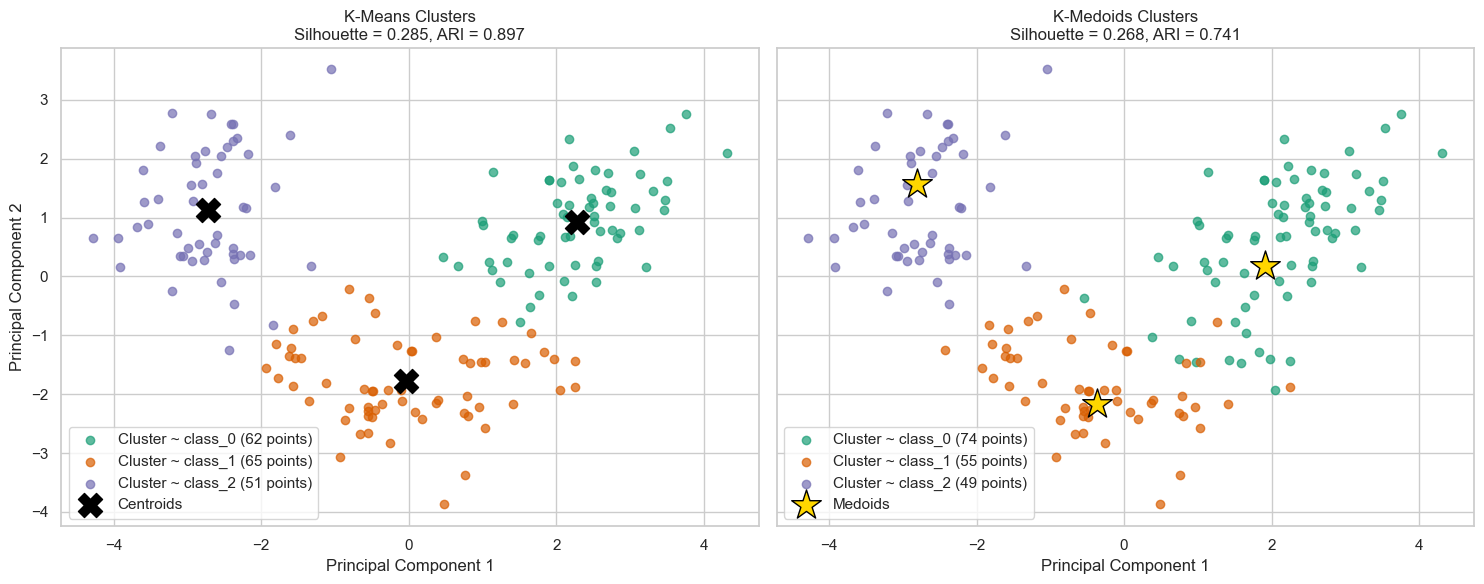

In [20]:
colors = ["#1b9e77", "#d95f02", "#7570b3"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

# K-Means plot
for c in range(3):
    points = X_pca[kmeans_matched == c]
    axes[0].scatter(points[:, 0], points[:, 1], color=colors[c], alpha=0.7,
                    label=f"Cluster ~ {wine.target_names[c]} ({len(points)} points)")
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker="X", s=300,
                color="black", label="Centroids")
axes[0].set_title(f"K-Means Clusters\nSilhouette = {kmeans_silhouette:.3f}, ARI = {kmeans_ari:.3f}")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(loc="lower left")

# K-Medoids plot
for c in range(3):
    points = X_pca[kmedoids_matched == c]
    axes[1].scatter(points[:, 0], points[:, 1], color=colors[c], alpha=0.7,
                    label=f"Cluster ~ {wine.target_names[c]} ({len(points)} points)")
axes[1].scatter(medoids_pca[:, 0], medoids_pca[:, 1], marker="*", s=500,
                color="gold", edgecolor="black", label="Medoids")
axes[1].set_title(f"K-Medoids Clusters\nSilhouette = {kmedoids_silhouette:.3f}, ARI = {kmedoids_ari:.3f}")
axes[1].set_xlabel("Principal Component 1")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

Both models find the same three groups: `class_2` on the left, `class_1` at the bottom and `class_0` on the right. The biggest difference is in the lower right. K-Means keeps those points in the `class_1` (orange) cluster, while K-Medoids puts them in the `class_0` (green) cluster, which grows from 62 to 74 points.

The K-Means centroids (black X) are in the middle of each group. The K-Medoids medoids (gold stars) are real data points, and the `class_0` medoid is closer to the lower-left edge of its group. This moves the border between the two clusters into the `class_1` area.

### 4.2 True classes and wrongly clustered points

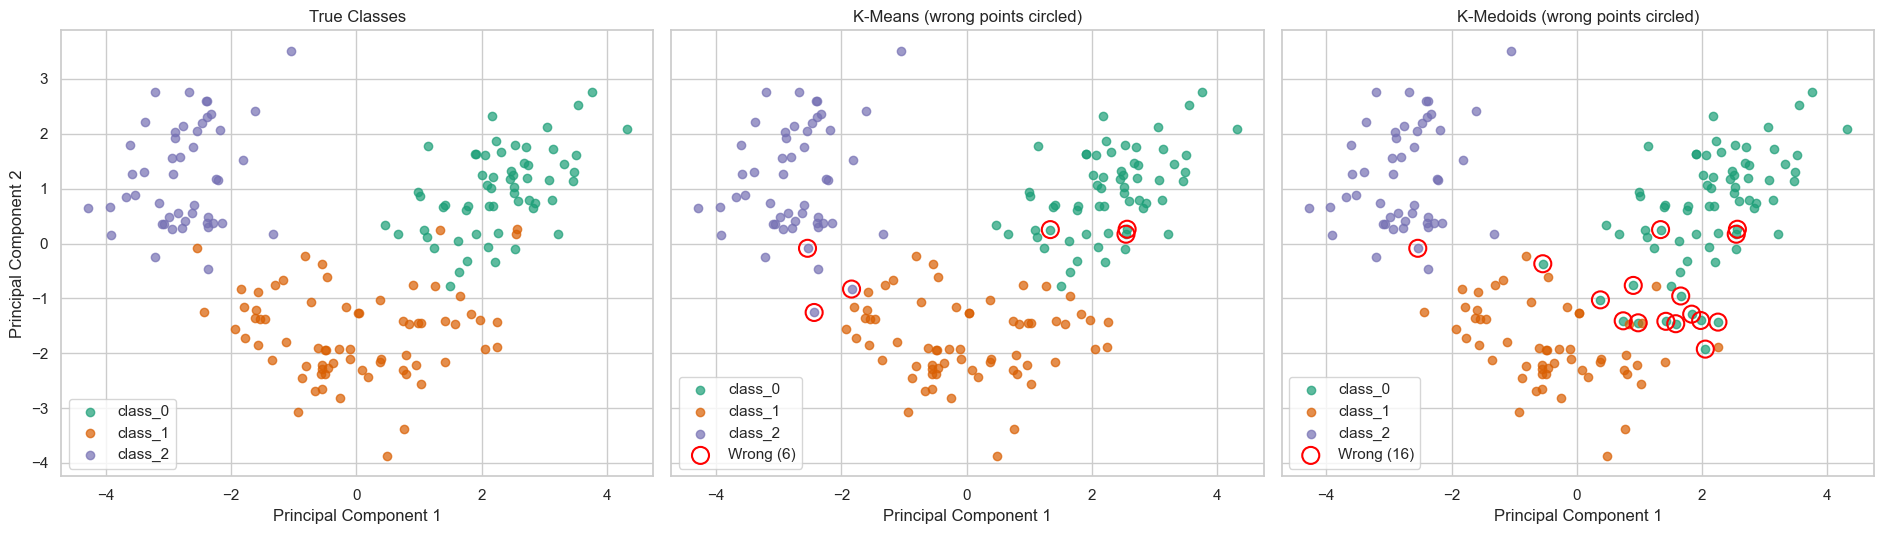

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)
plots = [("True Classes", y.values),
         ("K-Means (wrong points circled)", kmeans_matched),
         ("K-Medoids (wrong points circled)", kmedoids_matched)]

for ax, (title, labels) in zip(axes, plots):
    for c in range(3):
        points = X_pca[labels == c]
        ax.scatter(points[:, 0], points[:, 1], color=colors[c], alpha=0.7,
                   label=wine.target_names[c])
    if title != "True Classes":
        wrong = labels != y.values
        ax.scatter(X_pca[wrong, 0], X_pca[wrong, 1], s=150, facecolors="none",
                   edgecolors="red", linewidth=1.5, label=f"Wrong ({wrong.sum()})")
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.legend(loc="lower left")
axes[0].set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

All of the wrongly clustered points are `class_1` wines that sit close to another class. K-Means gets 6 wrong, and K-Medoids gets 16 wrong, most of them where `class_1` meets `class_0` in the lower right.

### 4.3 Comparing the metrics

In [22]:
results = pd.DataFrame({
    "Silhouette Score": [kmeans_silhouette, kmedoids_silhouette],
    "ARI": [kmeans_ari, kmedoids_ari],
    "Correct (%)": [100 * (kmeans_matched == y.values).mean(),
                    100 * (kmedoids_matched == y.values).mean()],
}, index=["K-Means", "K-Medoids"])
results.round(3)

,Silhouette Score,ARI,Correct (%)
K-Means,0.285,0.897,96.629
K-Medoids,0.268,0.741,91.011


### 4.4 Analysis

**Which algorithm produced better-defined clusters?**

K-Means did better on both metrics. Its silhouette score was slightly higher (0.285 vs. 0.268), so its clusters are a little more compact and better separated. Its ARI was much higher (0.897 vs. 0.741), so its clusters match the real wine classes much more closely: 96.6% correct compared with 91.0% for K-Medoids.

**What differences do you observe in cluster shapes or positioning?**

- **Center position:** K-Means centroids are averages, so they sit in the middle of each group, usually at a spot where there is no actual wine. K-Medoids medoids have to be real wines, so they can end up a bit off-center.
- **Cluster borders:** the `class_0` and `class_2` clusters are almost the same in both models. The main difference is the border between `class_0` and `class_1`. Each point goes to its closest center, so when the `class_0` medoid shifts, the border shifts too. As a result, the K-Medoids `class_0` cluster takes in about 15 `class_1` wines.
- **Shape:** both algorithms assign points to the nearest center, so both make round, convex clusters. Neither one can find long or curved clusters.

**When is K-Means or K-Medoids preferable?**

K-Means is a better choice when:
- the data is numeric and scaled, like this dataset;
- the clusters are fairly round and similar in size;
- the dataset is large, because K-Means is much faster. K-Medoids (PAM) needs the distance between every pair of points, which gets slow with a lot of data;
- there are few strong outliers. The outliers in this dataset were not extreme enough to hurt K-Means.

K-Medoids is a better choice when:
- the data has many strong outliers, since a medoid can't be pulled away by extreme values the way a mean can;
- you need a different distance measure, such as Manhattan distance or a distance for categorical data. K-Medoids works with any distance, but K-Means needs to calculate averages;
- you want each cluster to be represented by a real example (here, an actual wine), which is easier to explain;
- the dataset is small or medium sized.

## Conclusion

- The Wine dataset had no missing values or duplicates. I kept the few outliers because they looked like real measurements, and I standardized the features because their scales were very different.
- k = 3 matched the number of classes and also gave the best silhouette score.
- K-Means (silhouette 0.285, ARI 0.897) performed better than K-Medoids (silhouette 0.268, ARI 0.741) and matched 96.6% of the true classes.
- For clean, scaled, numeric data like this, K-Means is the better and faster choice. K-Medoids would be more useful for data with many outliers, mixed data types, or when a different distance measure is needed.